<center><h1>Zhu_Lingfei_HW7</h1></center>

Name: Lingfei Zhu
<br>
Github Username: youth0505
<br>
USC ID: 8599420339

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import numpy as np, pandas as pd
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.spatial.distance import squareform
import matplotlib.pyplot as plt

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df = pd.read_csv('../data/Anuran Calls (MFCCs)/Frogs_MFCCs.csv')
X = df.iloc[:, :22]
labels = ['Family', 'Genus', 'Species']
Y = df[labels]

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, train_size=0.7, random_state=42)

### (b) Train a classifier for each label

#### (i) Research

In a multi-label problem every instance has several labels, here (Family, Genus, Species), so there is more than one way to score a prediction.

Exact match ratio is the fraction of instances where all three labels are correct. If Species is wrong, the whole instance counts as wrong.

Hamming loss is the fraction of labels that are wrong, over all instances and all labels:

$$\text{Hamming loss} = \frac{1}{nL}\sum_{i=1}^{n}\sum_{j=1}^{L}\mathbb{1}\left(y_{ij}\neq\hat{y}_{ij}\right)$$

where n is the number of instances and L = 3. Hamming score is 1 - Hamming loss, the fraction of labels that are correct. For a single instance, the Hamming distance is the number of labels that differ between the true triplet and the predicted one (0 to 3), so the average distance divided by 3 gives the Hamming loss.

Exact match is stricter than Hamming score, so it is never higher. I report all of these on the training and test sets.

#### (ii) Train a SVM for each of the labels

In [3]:
def multilabel_metrics(Y_true, Y_pred):
    match = (np.asarray(Y_true) == np.asarray(Y_pred))
    exact = match.all(axis=1).mean()
    h_score = match.mean()
    return {'exact_match': exact, 'hamming_score': h_score, 'hamming_loss': 1 - h_score}

def fit_rbf(scaled):
    sigmas = [0.1, 0.3, 0.5, 1, 2, 5]
    grid = {'svm__estimator__C': 10.0**np.arange(-1, 4),
            'svm__estimator__gamma': [1/(2*s**2) for s in sigmas]}
    preds_tr, preds_te, best = {}, {}, {}
    for lab in labels:
        pipe = Pipeline([('scale', StandardScaler() if scaled else 'passthrough'),
                         ('svm', OneVsRestClassifier(SVC(kernel='rbf')))])
        gs = GridSearchCV(pipe, grid, cv=10, n_jobs=-1).fit(X_train, Y_train[lab])
        preds_tr[lab] = gs.predict(X_train)
        preds_te[lab] = gs.predict(X_test)
        best[lab] = gs.best_params_
    return pd.DataFrame(preds_tr), pd.DataFrame(preds_te), best

for scaled in [False, True]:
    ptr, pte, best = fit_rbf(scaled)
    print('scaled =', scaled, best)
    print('train', multilabel_metrics(Y_train, ptr))
    print('test ', multilabel_metrics(Y_test, pte))

scaled = False {'Family': {'svm__estimator__C': np.float64(10.0), 'svm__estimator__gamma': 2.0}, 'Genus': {'svm__estimator__C': np.float64(10.0), 'svm__estimator__gamma': 2.0}, 'Species': {'svm__estimator__C': np.float64(10.0), 'svm__estimator__gamma': 2.0}}
train {'exact_match': np.float64(0.999801429706116), 'hamming_score': np.float64(0.999801429706116), 'hamming_loss': np.float64(0.00019857029388403724)}
test  {'exact_match': np.float64(0.9888837424733673), 'hamming_score': np.float64(0.9921259842519685), 'hamming_loss': np.float64(0.007874015748031482)}
scaled = True {'Family': {'svm__estimator__C': np.float64(100.0), 'svm__estimator__gamma': 0.02}, 'Genus': {'svm__estimator__C': np.float64(100.0), 'svm__estimator__gamma': 0.02}, 'Species': {'svm__estimator__C': np.float64(100.0), 'svm__estimator__gamma': 0.02}}
train {'exact_match': np.float64(1.0), 'hamming_score': np.float64(1.0), 'hamming_loss': np.float64(0.0)}
test  {'exact_match': np.float64(0.9865678554886521), 'hamming_sc

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [4]:
def fit_l1(extra_steps=[]):
    grid = {'svm__C': 10.0**np.arange(-3, 4)}
    ptr, pte, best = {}, {}, {}
    for lab in labels:
        pipe = Pipeline([('scale', StandardScaler())] + extra_steps +
                        [('svm', LinearSVC(penalty='l1', dual=False, max_iter=10000))])
        gs = GridSearchCV(pipe, grid, cv=10, n_jobs=-1).fit(X_train, Y_train[lab])
        ptr[lab], pte[lab], best[lab] = gs.predict(X_train), gs.predict(X_test), gs.best_params_
    return pd.DataFrame(ptr), pd.DataFrame(pte), best

ptr, pte, best = fit_l1()

print("Best Parameters:", best)
print("Training Metrics:", multilabel_metrics(Y_train, ptr))
print("Testing Metrics:", multilabel_metrics(Y_test, pte))

Best Parameters: {'Family': {'svm__C': np.float64(1.0)}, 'Genus': {'svm__C': np.float64(10.0)}, 'Species': {'svm__C': np.float64(1.0)}}
Training Metrics: {'exact_match': np.float64(0.9243447180301827), 'hamming_score': np.float64(0.9539978819168652), 'hamming_loss': np.float64(0.04600211808313481)}
Testing Metrics: {'exact_match': np.float64(0.9133858267716536), 'hamming_score': np.float64(0.9431835726416551), 'hamming_loss': np.float64(0.05681642735834491)}


#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [5]:
def fit_l1_smote():
    grid = {'svm__C': 10.0**np.arange(-3, 4)}
    ptr, pte, best = {}, {}, {}
    for lab in labels:
        pipe = ImbPipeline([('scale', StandardScaler()),
                            ('smote', SMOTE(random_state=0)),
                            ('svm', LinearSVC(penalty='l1', dual=False, max_iter=10000))])
        gs = GridSearchCV(pipe, grid, cv=10, n_jobs=-1).fit(X_train, Y_train[lab])
        ptr[lab], pte[lab], best[lab] = gs.predict(X_train), gs.predict(X_test), gs.best_params_
    return pd.DataFrame(ptr), pd.DataFrame(pte), best

ptr_smote, pte_smote, best_smote = fit_l1_smote()

print("Best Parameters:", best_smote)
print("Training Metrics:",
      multilabel_metrics(Y_train, ptr_smote))
print("Testing Metrics:",
      multilabel_metrics(Y_test, pte_smote))

Best Parameters: {'Family': {'svm__C': np.float64(10.0)}, 'Genus': {'svm__C': np.float64(1.0)}, 'Species': {'svm__C': np.float64(10.0)}}
Training Metrics: {'exact_match': np.float64(0.869142176330421), 'hamming_score': np.float64(0.9351998940958433), 'hamming_loss': np.float64(0.06480010590415675)}
Testing Metrics: {'exact_match': np.float64(0.8540991199629459), 'hamming_score': np.float64(0.9228037671761617), 'hamming_loss': np.float64(0.07719623282383825)}


Compared with the original L1-penalized SVM, the SMOTE-based model achieved lower overall classification performance on the test set. The Exact Match Ratio decreased from 0.9129 to 0.8541, while the Hamming Score decreased from 0.9432 to 0.9228. Correspondingly, the Hamming Loss increased from 0.0568 to 0.0772.

These results suggest that SMOTE did not improve the overall multi-label classification performance in this experiment. Although SMOTE was applied to address class imbalance, oversampling may have introduced additional synthetic samples that did not sufficiently improve the decision boundaries. Further class-specific evaluation, such as per-class precision and recall, would be needed to determine whether minority-class classification improved.

Overall, the original L1-penalized SVM performed better in terms of the three overall evaluation metrics.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

Optimal K: 4
Best Silhouette Score: 0.3787509343305295


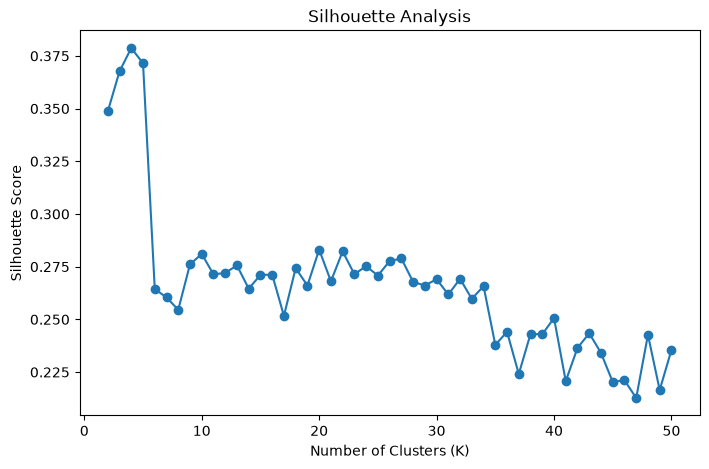

In [6]:
X_all = df.iloc[:, :22].values
ks = list(range(2, 51))
sil = [silhouette_score(X_all, KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(X_all))
       for k in ks]
best_k = ks[int(np.argmax(sil))]
print("Optimal K:", best_k)
print("Best Silhouette Score:", max(sil))

plt.figure(figsize=(8, 5))
plt.plot(ks, sil, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.show()

### (b) Determine which family is the majority

In [7]:
def cluster_majority(seed):
    cl = KMeans(n_clusters=best_k, n_init=10, random_state=seed).fit_predict(X_all)
    tmp = df[labels].copy()
    tmp['cluster'] = cl
    majority = tmp.groupby('cluster')[labels].agg(lambda s: s.mode().iloc[0])
    return cl, majority

cl0, majority0 = cluster_majority(0)
print(majority0.assign(size=np.bincount(cl0)))

                  Family      Genus                 Species  size
cluster                                                          
0        Leptodactylidae  Adenomera  AdenomeraHylaedactylus  3568
1                Hylidae  Hypsiboas       HypsiboasCordobae  1982
2          Dendrobatidae   Ameerega      Ameeregatrivittata  1031
3                Hylidae  Hypsiboas    HypsiboasCinerascens   614


For each cluster, the majority label of Family, Genus, and Species is determined independently using the mode of the corresponding true labels.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [8]:
def hamming_metrics(cl, majority):
    pred = majority.loc[cl].values
    true = df[labels].values
    mismatch = (pred != true)
    dist = mismatch.sum(axis=1).mean()
    loss = mismatch.mean()
    return dist, 1 - loss, loss

res = []
for seed in range(50):
    cl, majority = cluster_majority(seed)
    res.append(hamming_metrics(cl, majority))
res = np.array(res)

summary = pd.DataFrame({'mean': res.mean(axis=0), 'std': res.std(axis=0)},
                       index=['Hamming distance', 'Hamming score', 'Hamming loss'])
print(summary)

                      mean       std
Hamming distance  0.671889  0.016807
Hamming score     0.776037  0.005602
Hamming loss      0.223963  0.005602


## 3. ISLR 12.6.2

**(a)** With complete linkage, the first fusion is observations 1 and 2 at height 0.3, since d(1,2) = 0.3 is the smallest dissimilarity. After that, d({1,2},3) = max(0.4, 0.5) = 0.5, d({1,2},4) = max(0.7, 0.8) = 0.8 and d(3,4) = 0.45. The smallest is 0.45, so 3 and 4 fuse at height 0.45. The last fusion joins {1,2} and {3,4} at height max(0.4, 0.5, 0.7, 0.8) = 0.8.

**(b)** With single linkage, 1 and 2 fuse first at 0.3. Then d({1,2},3) = min(0.4, 0.5) = 0.4, d({1,2},4) = min(0.7, 0.8) = 0.7 and d(3,4) = 0.45, so observation 3 joins {1,2} at height 0.4. Finally d({1,2,3},4) = min(0.7, 0.8, 0.45) = 0.45, so observation 4 joins at height 0.45.

**(c)** Cutting the dendrogram in (a) into two clusters gives {1, 2} and {3, 4}.

**(d)** Cutting the dendrogram in (b) into two clusters gives {1, 2, 3} and {4}.

**(e)** At every fusion the two branches can be swapped without changing the tree. For example, swapping the two branches of the final fusion in (a) gives the leaf order 3, 4, 1, 2, and swapping 1 and 2 gives 2, 1, 3, 4. The fusion heights stay the same, so the clustering is the same.

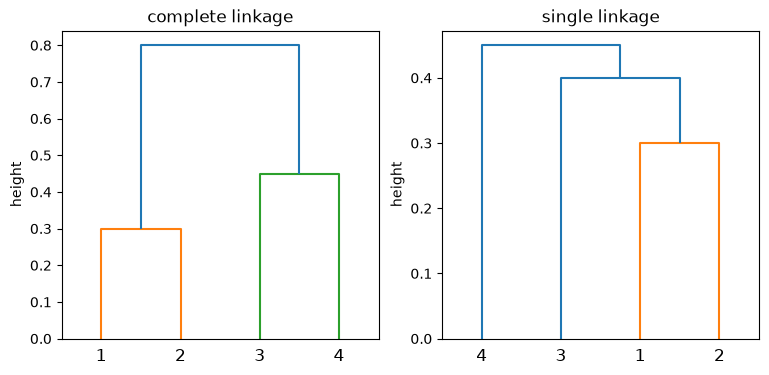

In [9]:
D = np.array([[0,   0.3, 0.4, 0.7],
              [0.3, 0,   0.5, 0.8],
              [0.4, 0.5, 0,   0.45],
              [0.7, 0.8, 0.45, 0]])
d = squareform(D)

fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, method in zip(axes, ['complete', 'single']):
    Z = linkage(d, method=method)
    dendrogram(Z, labels=[1, 2, 3, 4], ax=ax)
    ax.set_title(f'{method} linkage')
    ax.set_ylabel('height')
plt.show()